In [1]:
import pandas as pd
import os
from fastai.vision.all import *

In [2]:
Dataframe_path = '../image_data_assorted.csv'

if os.path.exists(Dataframe_path):
    print("The file exists.")
else:
    %run ../Generating_basic_data.ipynb

The file exists.


In [3]:

df = pd.read_csv('../image_data_assorted.csv')

In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,57,82,279,3249,228,185193,../images_assorted/image_1.png,../masks_assorted/mask_1.png,square
1,94,347,290,8836,376,830584,../images_assorted/image_2.png,../masks_assorted/mask_2.png,square
2,42,79,332,1764,168,74088,../images_assorted/image_3.png,../masks_assorted/mask_3.png,square
3,88,248,182,24316,276,2853096,../images_assorted/image_4.png,../masks_assorted/mask_4.png,circle
4,74,430,381,17195,232,1696538,../images_assorted/image_5.png,../masks_assorted/mask_5.png,circle


In [5]:
def get_inputs(row):
    # Convert image path to PILImage
    image_data = PILImage.create(row['image_path'])
    return image_data 

def get_target(row):
    # Convert image path to PILImage
    target_data = row['mask_path']
    return target_data

In [6]:
codes = ['blank','background', 'object'] # remember 0 is first entry so pixels 1, 2 ,3 etc need a dummy entry for 0

dblock = DataBlock(
    blocks=(ImageBlock, MaskBlock(codes=codes)),  # Image input and auxiliary input
    get_x=get_inputs,  # Get both the image path and the auxiliary input
    get_y=get_target,  # Get the radius value from the dataframe
    #splitter=RandomSplitter(valid_pct=0.2, seed=42),  # Split into train and validation sets
    #item_tfms=Resize(512)  # Resize images to 512x512

)

In [7]:
dls = dblock.dataloaders(df, bs=4)


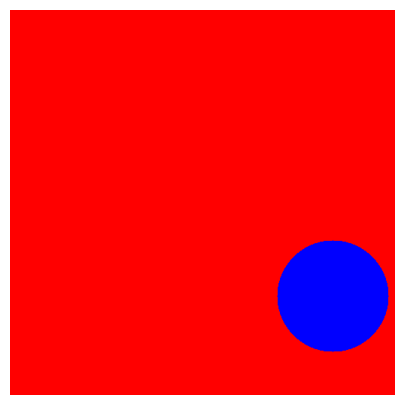

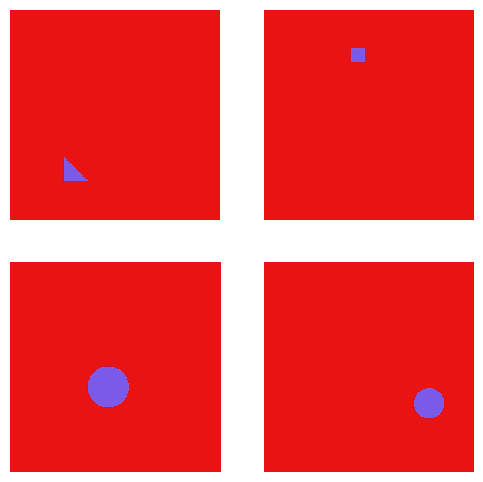

In [8]:

image_paths = df['image_path']
image_data = PILImage.create(image_paths[4])
image_data.show()

#print('filtered batched data below')

dls.show_batch()

In [9]:
# Create and train the learner
learn = unet_learner(dls, resnet34, metrics=Dice)


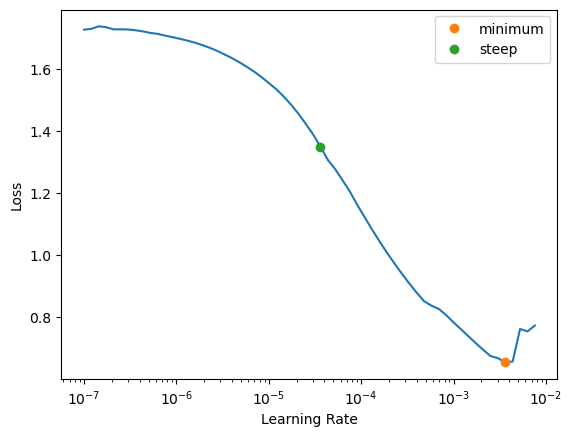

In [10]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

In [11]:
learn.fine_tune(10, base_lr=lr_steep)

epoch,train_loss,valid_loss,dice,time
0,0.043766,0.001783,1.055542,00:44


epoch,train_loss,valid_loss,dice,time
0,0.000773,0.000566,1.055924,00:46
1,0.000310,0.000234,1.055973,00:47
2,0.000114,0.000085,1.055974,00:47
3,0.000058,0.000052,1.055974,00:47
4,0.000036,0.000035,1.055981,00:47
5,0.000028,0.000025,1.055987,00:47
6,0.000021,0.000021,1.055988,00:47
7,0.000021,0.000022,1.055988,00:47
8,0.000014,0.000024,1.055990,00:46
9,0.000016,0.000021,1.055988,00:46


<bound method Recorder.plot_loss of Recorder>


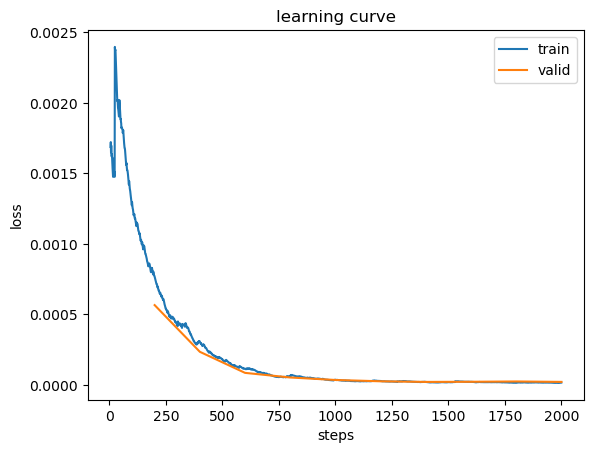

In [12]:
# Plot the losses
learn.recorder.plot_loss()
print(learn.recorder.plot_loss)
# Set the y-axis limits (replace with your desired limits)
#plt.ylim(0, 5)  # sets y-axis limits 
# Show the plot with updated y-limits
plt.show()

In [13]:


learn.export('exported_segmentation_model.pkl')
 


In [14]:
# import

learn2 = load_learner('exported_segmentation_model.pkl')   # using learner2 to show its loading


C:\Users\bowan\anaconda3\Lib\site-packages\fastai\learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


<class 'fastai.torch_core.TensorMask'>
<class 'fastai.torch_core.TensorBase'>
<class 'fastai.torch_core.TensorBase'>
torch.Size([512, 512])
torch.Size([512, 512])
torch.Size([3, 512, 512])


<Axes: >

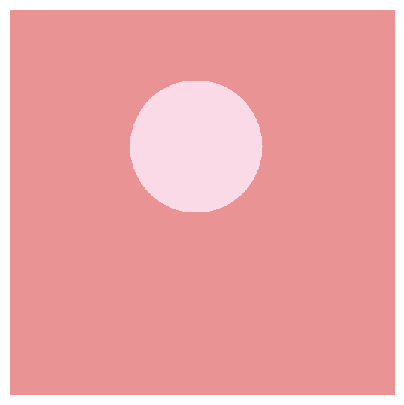

In [15]:
# just getting a random image from df
image_paths = df['image_path']
image_data = PILImage.create(image_paths[3])
prediction, classid, probablities = learn2.predict(image_data)

print(type(prediction))
print(type(classid))
print(type(probablities))

print(prediction.shape)
print(classid.shape)
print(probablities.shape)

prediction.show()
#print(prediction.shape)
#print(type(prediction))

<Axes: >

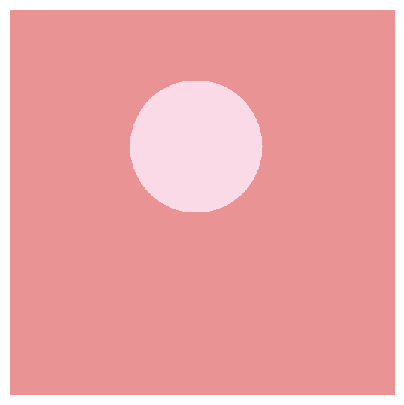

In [16]:
prediction.show()

<Axes: >

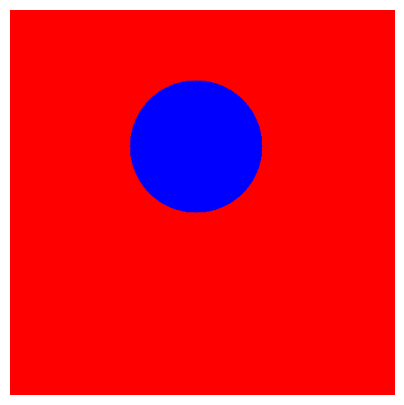

In [18]:
image_data.show()